# Music Tribes Explorer

Unsupervised clustering (K-Means) + dimensionality reduction (PCA / UMAP) on the
Spotify 1921–2020 corpus.

Runs end-to-end from a clean kernel. Inputs are Person 1's frozen artifacts
(`tracks_100k.parquet`, `scaler.joblib`) — nothing is re-preprocessed and the scaler is
never re-fit.

**Outputs written to `OUT_DIR`:** `kmeans.joblib`, `tracks_clustered.parquet`,
`cluster_metadata.json`, `map_data.json`, cluster/decade CSV tables, and the report figures.

Requires: `pip install pandas pyarrow scikit-learn umap-learn matplotlib joblib`

In [1]:
import os, json, time, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, normalized_mutual_info_score,
                             adjusted_rand_score)
from sklearn.manifold import trustworthiness

SEED = 42                                   # shared project seed
DATA_DIR = "data"                           # Person 1's shared folder
OUT_DIR  = "outputs/music_tribes"
FIG_DIR  = f"{OUT_DIR}/figures"
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

AUDIO_FEATURES = ['danceability','energy','loudness','speechiness','acousticness',
                  'instrumentalness','liveness','valence','tempo','duration_ms',
                  'mode','time_signature']          # fixed order - the scaler expects it
CONT10 = [f for f in AUDIO_FEATURES if f not in ('mode','time_signature')]
RADAR_FEATURES = [f for f in CONT10 if f != 'duration_ms']   # radar charts + website profiles
K_FINAL = 6
PALETTE = ["#E4572E","#17BEBB","#2E4057","#F3A712","#7B2D8E","#4C9F70"]

plt.rcParams.update({"font.size": 9, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 150, "savefig.bbox": "tight"})

def save_fig(fig, filename):
    """Write a report figure to FIG_DIR and show it inline."""
    fig.savefig(f"{FIG_DIR}/{filename}")
    plt.show()

## 1. Load the shared artifacts

`scaler.joblib` is loaded, never fitted. `X` is the standardized 12-D matrix every module
in the project works in.

In [2]:
tracks = pd.read_parquet(f"{DATA_DIR}/tracks_100k.parquet")
scaler = joblib.load(f"{DATA_DIR}/scaler.joblib")

X   = scaler.transform(tracks[AUDIO_FEATURES].values)
X10 = X[:, [AUDIO_FEATURES.index(f) for f in CONT10]]   # same scaler, two columns dropped

print(tracks.shape, X.shape)
print("decade distribution preserved:", tracks.decade.value_counts().sort_index().to_dict())

(100001, 28) (100001, 12)
decade distribution preserved: {1920: 1253, 1930: 2223, 1940: 2840, 1950: 5993, 1960: 8144, 1970: 10629, 1980: 14119, 1990: 18613, 2000: 14664, 2010: 18215, 2020: 3308}


## 2. Choosing k — elbow, silhouette, Davies–Bouldin

K-Means for k = 2…15 with `n_init=10`. Silhouette is O(n²), so it is computed on a fixed
10,000-track subsample. The same sweep is run on the 10 continuous features for the
sensitivity analysis in §8.

In [3]:
def sweep(M, ks=range(2, 16)):
    rows = []
    for k in ks:
        km  = KMeans(n_clusters=k, random_state=SEED, n_init=10)
        lab = km.fit_predict(M)
        rows.append(dict(k=k, inertia=km.inertia_,
                         silhouette=silhouette_score(M, lab, sample_size=10000, random_state=SEED),
                         davies_bouldin=davies_bouldin_score(M, lab),
                         calinski_harabasz=calinski_harabasz_score(M, lab),
                         smallest_cluster=int(np.bincount(lab).min())))
    return pd.DataFrame(rows)

sw12 = sweep(X);   sw12.to_csv(f"{OUT_DIR}/k_sweep_12feature.csv", index=False)
sw10 = sweep(X10); sw10.to_csv(f"{OUT_DIR}/k_sweep_10feature.csv", index=False)
sw12.round(4)

,k,inertia,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster
0,2,993801.5009,0.1987,2.0526,20303.9615,38272
1,3,895540.5267,0.2137,1.7101,16751.7512,5047
2,4,830636.2680,0.1827,1.7834,14644.8739,4998
3,5,770566.9487,0.1559,1.9086,13788.5680,4937
4,6,726117.0650,0.1610,1.7884,12930.2468,4820
5,7,690819.2419,0.1611,1.7678,12177.2043,4706
6,8,659026.2548,0.1562,1.6518,11630.1874,1268
7,9,628020.7474,0.1537,1.6319,11295.7605,307
8,10,604595.2441,0.1548,1.6146,10860.1053,300
9,11,581010.8473,0.1470,1.5540,10576.6235,296


In [4]:
def knee(df):
    """Elbow point = the k whose inertia is furthest from the chord joining the endpoints."""
    k = df.k.values.astype(float); I = df.inertia.values
    x = (k-k.min())/(k.max()-k.min()); y = (I-I.min())/(I.max()-I.min())
    d = np.abs((x[-1]-x[0])*(y[0]-y)-(x[0]-x)*(y[-1]-y[0]))/np.hypot(x[-1]-x[0], y[-1]-y[0])
    return int(k[d.argmax()])

print("knee (12 features):", knee(sw12), "| knee (10 features):", knee(sw10))
print("silhouette argmax  :", int(sw12.loc[sw12.silhouette.idxmax(), 'k']))

knee (12 features): 6 | knee (10 features): 6
silhouette argmax  : 3


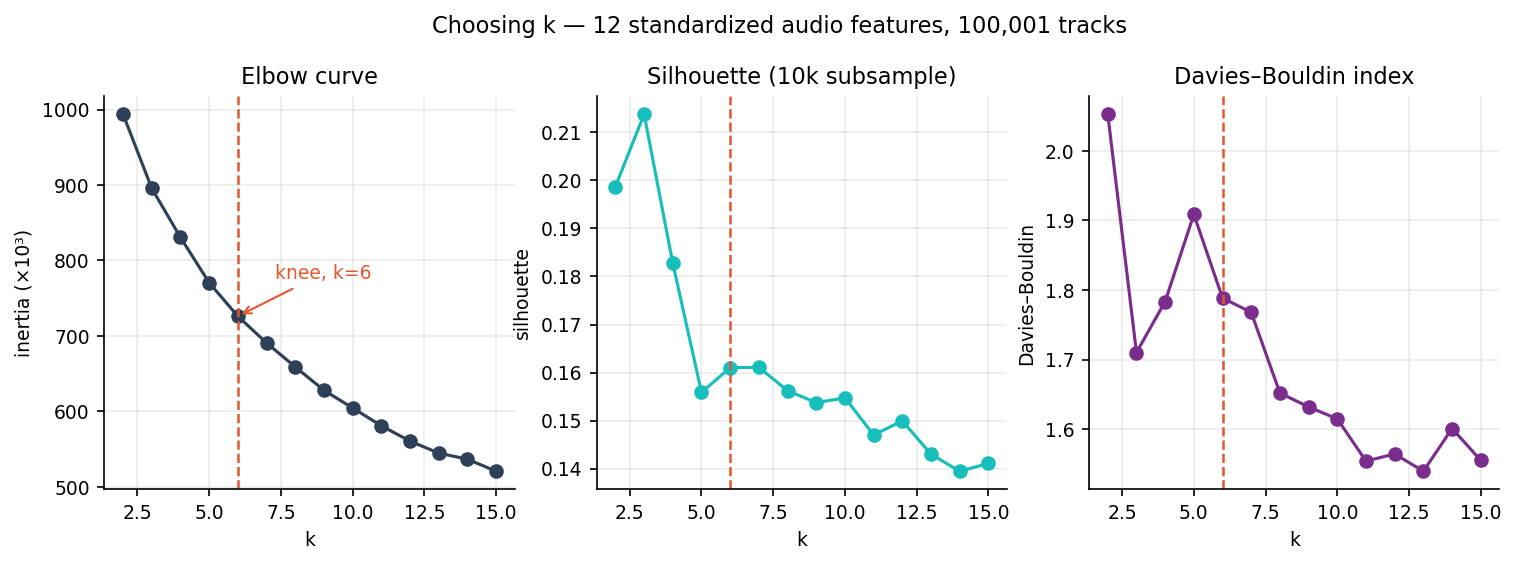

In [5]:
knee_k = knee(sw12)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
ax[0].plot(sw12.k, sw12.inertia/1e3, "o-", color="#2E4057")
ax[0].axvline(K_FINAL, color="#E4572E", ls="--", lw=1.2)
ax[0].annotate(f"knee, k={knee_k}",
               (knee_k, sw12.inertia[sw12.k == knee_k].iloc[0]/1e3),
               textcoords="offset points", xytext=(18, 18), color="#E4572E",
               arrowprops=dict(arrowstyle="->", color="#E4572E"))
ax[0].set(xlabel="k", ylabel="inertia (×10³)", title="Elbow curve")
ax[1].plot(sw12.k, sw12.silhouette, "o-", color="#17BEBB")
ax[1].axvline(K_FINAL, color="#E4572E", ls="--", lw=1.2)
ax[1].set(xlabel="k", ylabel="silhouette", title="Silhouette (10k subsample)")
ax[2].plot(sw12.k, sw12.davies_bouldin, "o-", color="#7B2D8E", label="Davies–Bouldin (↓)")
ax[2].axvline(K_FINAL, color="#E4572E", ls="--", lw=1.2)
ax[2].set(xlabel="k", ylabel="Davies–Bouldin", title="Davies–Bouldin index")
fig.suptitle(f"Choosing k — 12 standardized audio features, {len(tracks):,} tracks", y=1.04)
save_fig(fig, "01_elbow_silhouette.png")

**Decision.** Silhouette's global maximum is k = 3, but that solution is only
acoustic / loud-energetic / instrumental — too coarse for an explorer with a legend and per-tribe
pages. The elbow sits at k = 6 on both feature sets. k = 7 ties k = 6 on silhouette
(0.1611 vs 0.1610); at k = 8 a 1,268-track cluster appears that is defined by
`time_signature = 0` (a Spotify encoding artifact), and from k = 9 the smallest cluster
collapses to ~300 tracks. **k = 6** is the largest k that stays degeneracy-free, and it
coincides with the elbow. Committed.

In [6]:
kmeans = KMeans(n_clusters=K_FINAL, random_state=SEED, n_init=10).fit(X)
labels = kmeans.labels_
tracks["cluster_id"] = labels
tracks["dist_to_centroid"] = np.linalg.norm(X - kmeans.cluster_centers_[labels], axis=1)
joblib.dump(kmeans, f"{OUT_DIR}/kmeans.joblib")

print("silhouette      ", round(silhouette_score(X, labels, sample_size=10000, random_state=SEED), 4))
print("davies-bouldin  ", round(davies_bouldin_score(X, labels), 4))
print("calinski-harab. ", round(calinski_harabasz_score(X, labels), 1))
pd.Series(np.bincount(labels), name="tracks").to_frame().T

silhouette       0.161
davies-bouldin   1.7884
calinski-harab.  12930.2


,0,1,2,3,4,5
tracks,33914,8611,6500,24504,4820,21652


## 3. Cluster profiles

Centroids are reported twice: in standard deviations (what drove the split) and back in raw
units via `scaler.inverse_transform` (what a human can read).

In [7]:
centers_std = pd.DataFrame(kmeans.cluster_centers_, columns=AUDIO_FEATURES)
centers_raw = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=AUDIO_FEATURES)
centers_std.to_csv(f"{OUT_DIR}/cluster_centroids_standardized.csv", index_label="cluster_id")
centers_raw.to_csv(f"{OUT_DIR}/cluster_centroids_raw_units.csv", index_label="cluster_id")
centers_std.round(2)

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,mode,time_signature
0,0.34,0.59,0.50,-0.19,-0.57,-0.24,-0.26,0.44,0.22,-0.03,0.72,0.19
1,-0.84,-1.06,-1.32,-0.28,1.03,2.64,-0.24,-0.64,-0.33,0.15,0.04,-0.22
2,-0.41,0.56,0.31,-0.06,-0.26,-0.09,2.69,-0.08,0.12,0.39,0.12,0.09
3,-0.52,-0.98,-0.55,-0.30,0.87,-0.33,-0.25,-0.62,-0.23,-0.05,0.19,-0.24
4,0.61,-0.57,-1.06,4.04,0.52,-0.41,0.87,0.04,-0.55,-0.64,0.02,-0.74
5,0.37,0.56,0.49,-0.14,-0.55,-0.18,-0.23,0.27,0.13,0.06,-1.38,0.20


In [8]:
names = json.load(open(f"{OUT_DIR}/cluster_names.json"))   # authored by hand from these profiles, see §4
NAME   = {int(k): v["name"] for k, v in names.items()}
LABELS = [f"{c} · {NAME[c]}" for c in range(K_FINAL)]
NAME

{0: 'Sunlit Anthems',
 1: 'Instrumental Meditations',
 2: 'Live on Stage',
 3: 'Acoustic Storytellers',
 4: 'Spoken Word & Audio Drama',
 5: 'Midnight Anthems'}

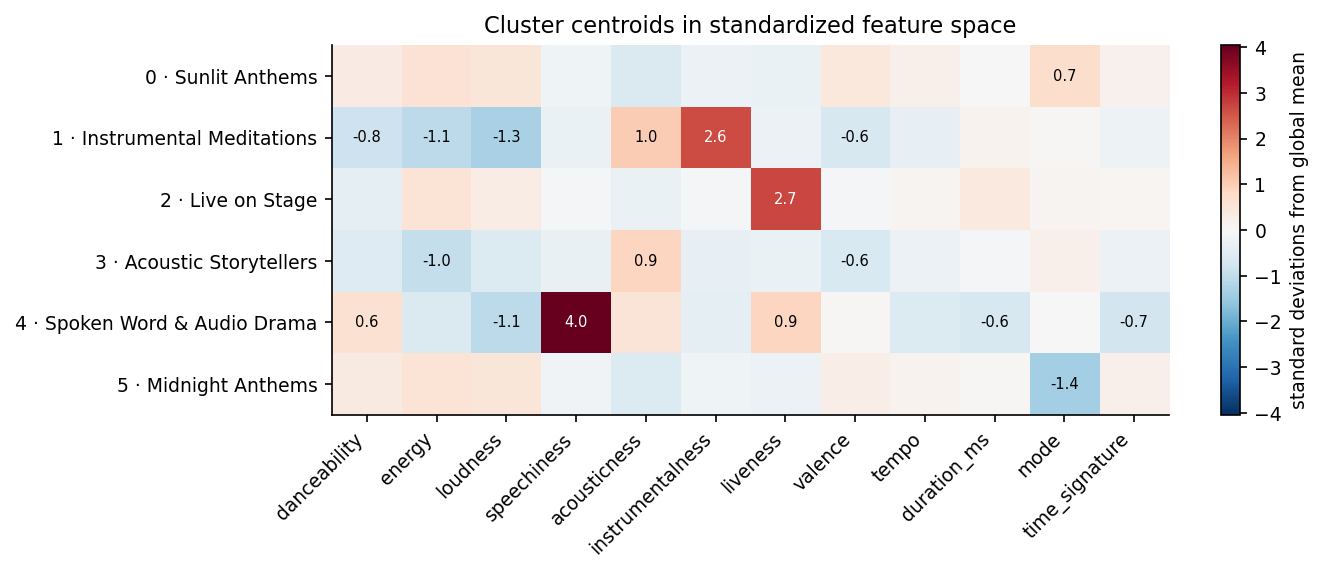

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.2))
M = centers_std[AUDIO_FEATURES].values
v = np.abs(M).max()
im = ax.imshow(M, cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto")
ax.set_xticks(range(len(AUDIO_FEATURES)))
ax.set_xticklabels(AUDIO_FEATURES, rotation=45, ha="right")
ax.set_yticks(range(K_FINAL))
ax.set_yticklabels(LABELS)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        if abs(M[i, j]) > 0.6:
            ax.text(j, i, f"{M[i,j]:.1f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(M[i, j]) > v*.6 else "black")
ax.grid(False)
fig.colorbar(im, label="standard deviations from global mean")
ax.set_title("Cluster centroids in standardized feature space")
save_fig(fig, "02_centroid_heatmap.png")

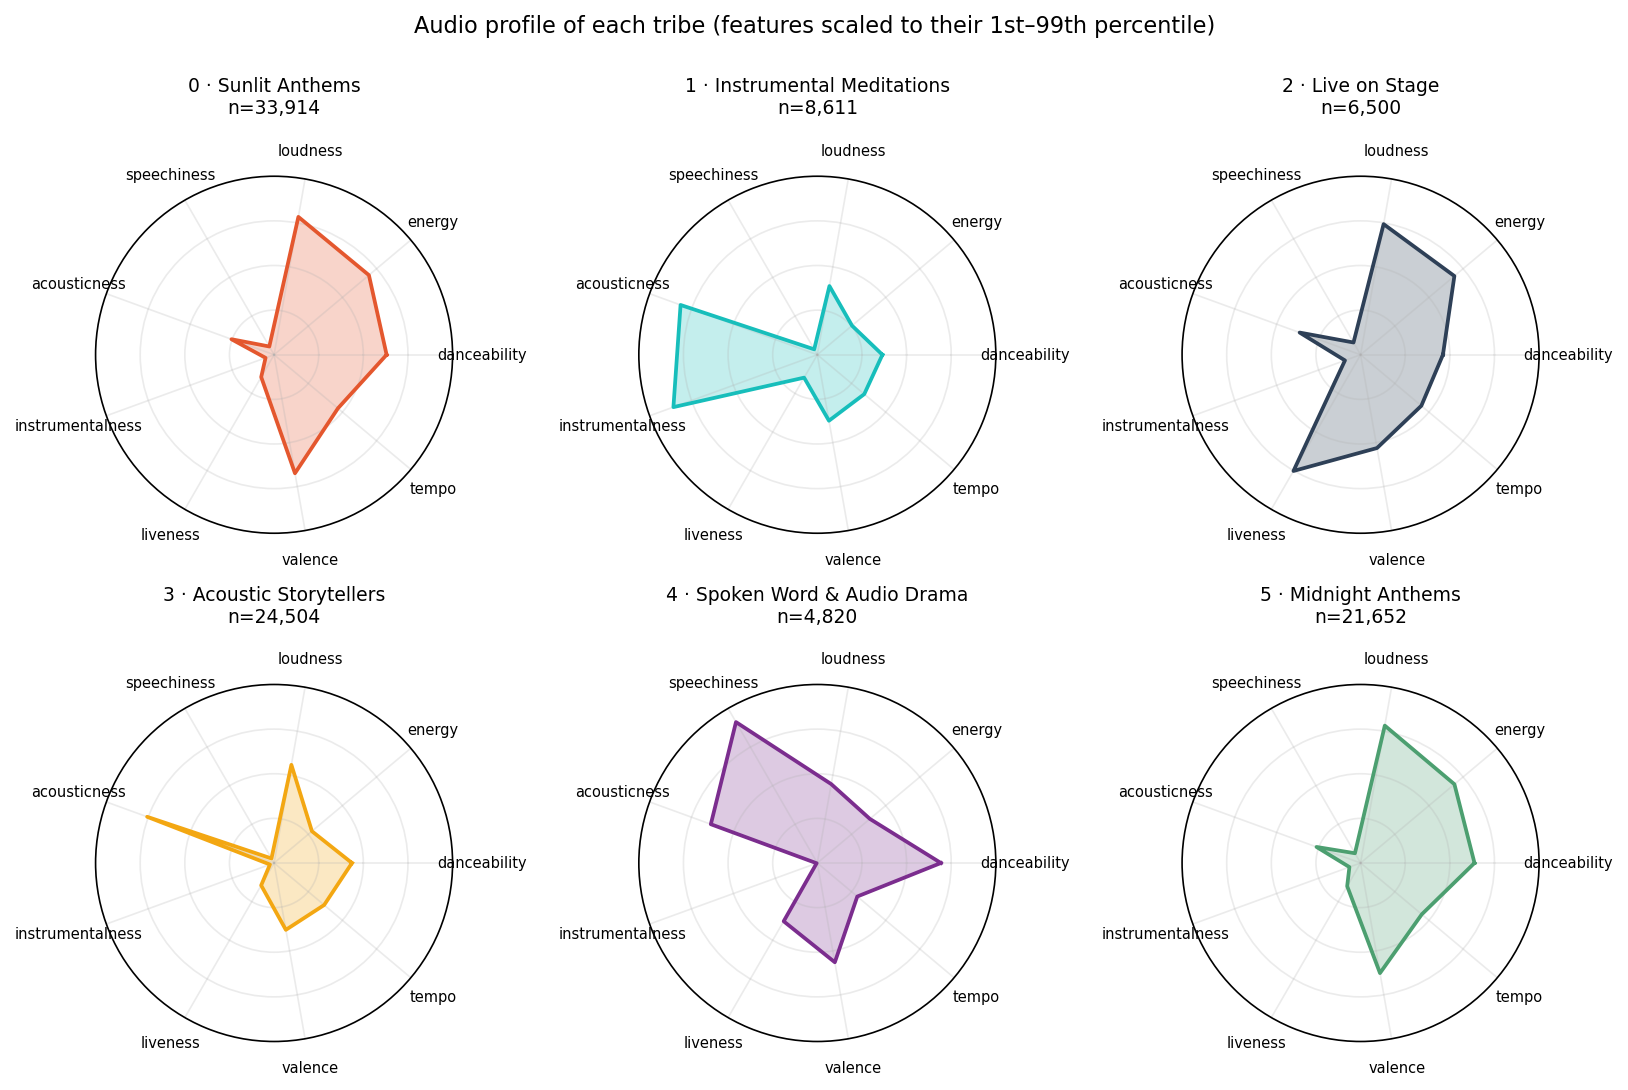

In [10]:
q = tracks[RADAR_FEATURES].quantile([0.01, 0.99])
radar = tracks.groupby("cluster_id")[RADAR_FEATURES].mean()
radar = ((radar - q.loc[0.01]) / (q.loc[0.99] - q.loc[0.01])).clip(0, 1)
ang = np.linspace(0, 2*np.pi, len(RADAR_FEATURES), endpoint=False).tolist()
ang += ang[:1]
fig, axes = plt.subplots(2, 3, figsize=(11, 7.2), subplot_kw=dict(polar=True))
for c, a in zip(range(K_FINAL), axes.ravel()):
    vals = radar.loc[c].tolist(); vals += vals[:1]
    a.plot(ang, vals, color=PALETTE[c], lw=1.8)
    a.fill(ang, vals, color=PALETTE[c], alpha=.25)
    a.set_xticks(ang[:-1]); a.set_xticklabels(RADAR_FEATURES, size=7)
    a.set_yticks([.25, .5, .75]); a.set_yticklabels([], size=6); a.set_ylim(0, 1)
    a.set_title(f"{LABELS[c]}\nn={int((labels == c).sum()):,}", size=9, pad=14)
for a in axes.ravel()[K_FINAL:]:
    a.axis("off")
fig.suptitle("Audio profile of each tribe (features scaled to their 1st–99th percentile)", y=1.0)
fig.tight_layout()
save_fig(fig, "03_cluster_radar.png")

### Validation against human genre labels

The plan's test: does an unsupervised cluster line up with the genre labels in `artists.csv`?
Raw Spotify genres are far too fine-grained (thousands of strings like *mellow gold*,
*stride*), so each track's artist genres are mapped to one of nine coarse buckets by keyword.

In [11]:
BUCKETS = {
    'Hip-Hop / Rap':      ['hip hop','rap','trap','drill','grime'],
    'Electronic / Dance': ['edm','house','techno','trance','dubstep','electro','drum and bass','dance pop','dance rock'],
    'Rock / Metal':       ['rock','metal','punk','grunge'],
    'Classical':          ['classical','opera','baroque','orchestra','romantic era','choral','chamber'],
    'Jazz / Standards':   ['jazz','bebop','swing','adult standards','vocal jazz','lounge','bossa'],
    'Country / Folk':     ['country','folk','bluegrass','americana'],
    'Latin / World':      ['latin','salsa','tango','reggaeton','tropical','bolero','ranchera','mpb','samba','filmi'],
    'Pop':                ['pop'],
    'Spoken Word':        ['hoerspiel','reading','barnsagor','comedy','poetry','audiobook','spoken','kindermusik','barnmusik'],
}
def bucket(gs):
    for g in gs:                       # artist_genres is an ndarray, not a list
        for b, keys in BUCKETS.items():
            if any(kk in g for kk in keys):
                return b
    return None

tracks["genre_bucket"] = tracks["artist_genres"].apply(bucket)
m = tracks.genre_bucket.notna().values
print("labelled coverage", round(m.mean(), 3))
print("NMI(cluster, genre bucket)", round(normalized_mutual_info_score(tracks.genre_bucket[m], labels[m]), 4))
genre_ct = pd.crosstab(tracks.cluster_id, tracks.genre_bucket, normalize="index")
(genre_ct * 100).round(1)

labelled coverage 0.772
NMI(cluster, genre bucket) 0.1443


genre_bucket,Classical,Country / Folk,Electronic / Dance,Hip-Hop / Rap,Jazz / Standards,Latin / World,Pop,Rock / Metal,Spoken Word
cluster_id,,,,,,,,,
0,0.3,4.8,5.7,9.1,6.9,8.3,37.2,27.1,0.5
1,36.3,3.4,2.8,0.3,27.6,7.1,10.6,11.8,0.0
2,1.8,4.7,6.6,5.2,10.0,10.3,29.4,30.2,1.6
3,7.3,10.6,1.2,1.3,20.6,8.6,37.8,12.0,0.6
4,1.1,2.3,0.3,1.5,1.5,0.3,5.4,2.6,84.9
5,0.3,3.8,8.8,14.4,6.7,7.7,37.0,21.0,0.4


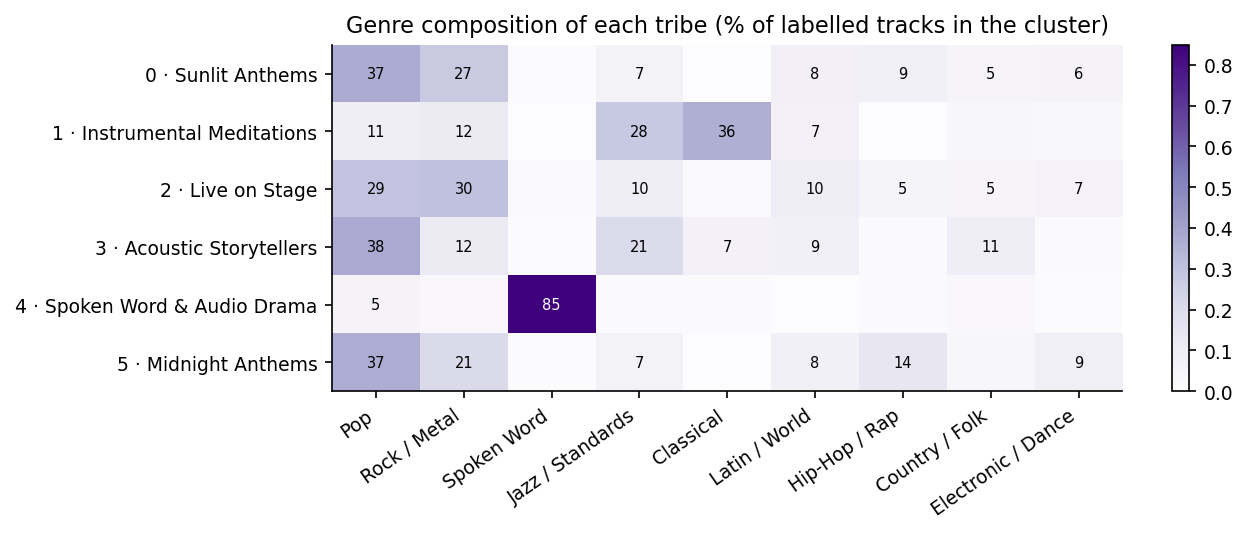

In [12]:
ct = genre_ct[genre_ct.sum().sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(8.5, 3.0))
im = ax.imshow(ct.values, cmap="Purples", vmin=0, vmax=ct.values.max(), aspect="auto")
ax.set_xticks(range(len(ct.columns))); ax.set_xticklabels(ct.columns, rotation=35, ha="right")
ax.set_yticks(range(K_FINAL)); ax.set_yticklabels(LABELS)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        if ct.values[i, j] > .04:
            ax.text(j, i, f"{100*ct.values[i,j]:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if ct.values[i, j] > ct.values.max()*.6 else "black")
ax.grid(False)
ax.set_title("Genre composition of each tribe (% of labelled tracks in the cluster)")
fig.colorbar(im)
save_fig(fig, "06_genre_validation.png")

### Per-cluster tables: genres, decades, artists, representative songs

In [13]:
exploded = tracks[["cluster_id","artist_genres"]].explode("artist_genres").dropna()
profiles = {}
for c in range(K_FINAL):
    sub    = tracks[tracks.cluster_id == c]
    inner  = sub[sub.dist_to_centroid <= sub.dist_to_centroid.quantile(0.25)]
    profiles[c] = dict(
        size=int(len(sub)), share=round(len(sub)/len(tracks), 4),
        mean_popularity=round(float(sub.popularity.mean()), 2),
        mean_pop_z=round(float(sub.pop_z.mean()), 3),
        median_year=int(sub.release_year.median()),
        centroid_standardized={f: round(float(v),3) for f,v in centers_std.loc[c].items()},
        centroid_raw_units={f: round(float(v),3) for f,v in centers_raw.loc[c].items()},
        top_genres=[[g,int(n)] for g,n in exploded[exploded.cluster_id==c]["artist_genres"]
                                            .value_counts().head(10).items()],
        top_genre_buckets=[[b,round(float(p),3)] for b,p in
                           sub.genre_bucket.value_counts(normalize=True).head(5).items()],
        top_decades=[[int(d),int(n)] for d,n in sub.decade.value_counts().head(5).items()],
        top_artists=[[a,int(n)] for a,n in sub.primary_artist_name.value_counts().head(20).items()],
        closest_songs=[{"name":r["name"],"artist":r.primary_artist_name,"year":int(r.release_year),
                        "popularity":int(r.popularity),"dist":round(float(r.dist_to_centroid),3)}
                       for _,r in sub.nsmallest(20,"dist_to_centroid").iterrows()],
        showcase_songs=[{"name":r["name"],"artist":r.primary_artist_name,"year":int(r.release_year),
                         "popularity":int(r.popularity)}
                        for _,r in inner.nlargest(20,"popularity").iterrows()],
    )
    print(f"{c}: n={len(sub):6d}  {[g for g,_ in profiles[c]['top_genres'][:4]]}")

0: n= 33914  ['rock', 'classic rock', 'mellow gold', 'album rock']
1: n=  8611  ['classical', 'cool jazz', 'jazz', 'adult standards']
2: n=  6500  ['rock', 'classic rock', 'album rock', 'mellow gold']
3: n= 24504  ['adult standards', 'vocal jazz', 'lounge', 'mellow gold']
4: n=  4820  ['hoerspiel', 'kleine hoerspiel', 'barnsagor', 'reading']
5: n= 21652  ['rock', 'filmi', 'latin', 'classic rock']


## 4. Naming the tribes

Names come from the centroid profile plus the genre and artist tables above — not from the
genre labels, which are only used to check the result afterwards.

| id | name | what defines it |
|----|------|-----------------|
| 0 | Sunlit Anthems | loud, energetic, danceable, **major key** |
| 1 | Instrumental Meditations | instrumentalness +2.6 SD; quiet, acoustic; classical and jazz |
| 2 | Live on Stage | liveness +2.7 SD — a recording context, not a genre |
| 3 | Acoustic Storytellers | acoustic, low energy, low valence, vocals present |
| 4 | Spoken Word & Audio Drama | speechiness +4.0 SD; 85% spoken-word labels; not music |
| 5 | Midnight Anthems | sonically identical to 0, **minor key**; skews later and more hip-hop |

Clusters 0 and 5 are a single sonic tribe split by key signature. §8 shows why, and what it
costs. `cluster_names.json` carries the names, taglines, descriptions and justifications
(loaded in §3 so the profile figures are labelled).

## 5. How each tribe moved across a century

In [14]:
by_dec_counts = pd.crosstab(tracks.decade, tracks.cluster_id)
by_dec_share  = pd.crosstab(tracks.decade, tracks.cluster_id, normalize="index")
by_dec_counts.to_csv(f"{OUT_DIR}/cluster_by_decade_counts.csv")
by_dec_share.round(4).to_csv(f"{OUT_DIR}/cluster_by_decade_share.csv")
(by_dec_share*100).round(1).rename(columns=NAME)

cluster_id,Sunlit Anthems,Instrumental Meditations,Live on Stage,Acoustic Storytellers,Spoken Word & Audio Drama,Midnight Anthems
decade,,,,,,
1920,8.3,29.1,1.5,28.4,28.7,3.9
1930,8.8,27.3,3.5,39.8,15.8,4.8
1940,6.3,39.6,3.8,42.5,3.5,4.3
1950,11.0,24.3,3.8,48.6,6.6,5.6
1960,22.5,15.0,5.8,43.1,3.0,10.7
1970,31.4,7.6,7.8,31.6,6.1,15.5
1980,34.8,5.2,6.4,22.8,10.9,19.9
1990,39.2,5.1,7.0,21.2,4.8,22.7
2000,43.0,3.0,7.8,15.5,1.4,29.4


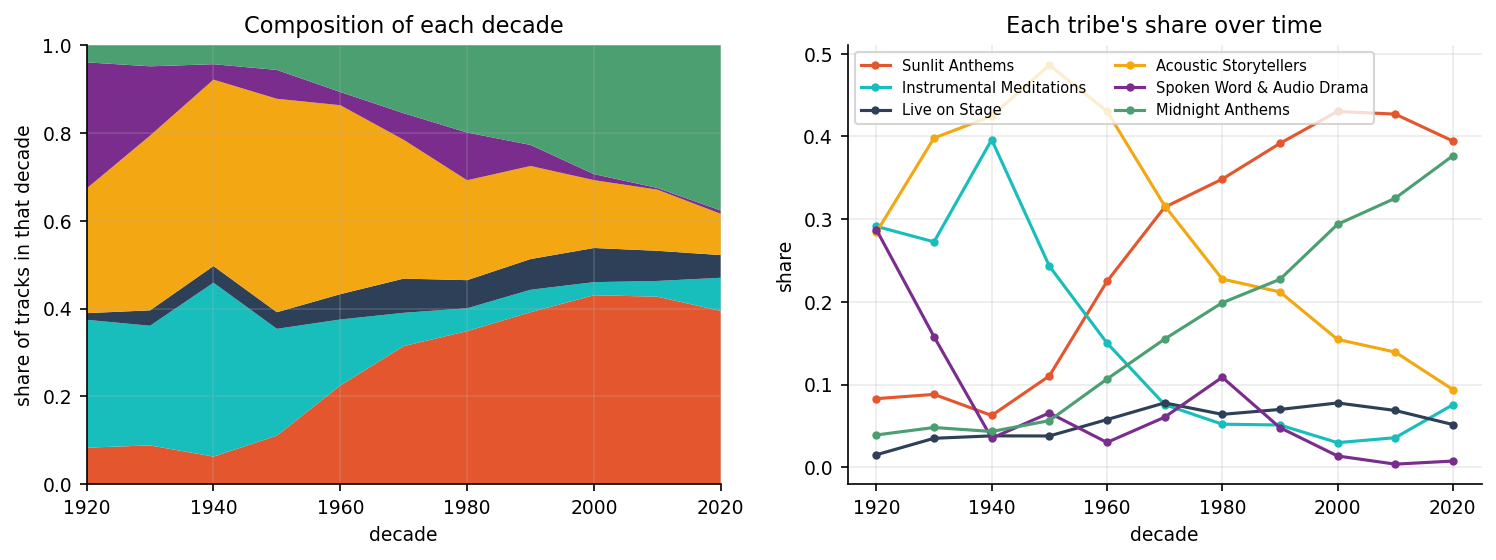

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].stackplot(by_dec_share.index, [by_dec_share[c] for c in range(K_FINAL)],
                colors=PALETTE, labels=[NAME[c] for c in range(K_FINAL)])
ax[0].set(xlabel="decade", ylabel="share of tracks in that decade", ylim=(0, 1),
          title="Composition of each decade")
ax[0].margins(x=0)
for c in range(K_FINAL):
    ax[1].plot(by_dec_share.index, by_dec_share[c], "o-", color=PALETTE[c], ms=3, label=NAME[c])
ax[1].set(xlabel="decade", ylabel="share", title="Each tribe's share over time")
ax[1].legend(fontsize=7, ncol=2)
save_fig(fig, "04_evolution_by_decade.png")

## 6. PCA — the linear baseline

In [16]:
pca = PCA(n_components=2, random_state=SEED)
P = pca.fit_transform(X)
tracks["pca_x"], tracks["pca_y"] = P[:,0], P[:,1]
joblib.dump(pca, f"{OUT_DIR}/pca.joblib")


['outputs/music_tribes/pca.joblib']

In [17]:

print("explained variance:", pca.explained_variance_ratio_.round(4),
      "| cumulative:", round(pca.explained_variance_ratio_.sum(), 4))
pd.DataFrame(pca.components_.T, index=AUDIO_FEATURES, columns=["PC1","PC2"]).round(3)

explained variance: [0.2454 0.1297] | cumulative: 0.3752


,PC1,PC2
danceability,0.294,0.468
energy,0.512,-0.142
loudness,0.477,-0.161
speechiness,-0.043,0.549
acousticness,-0.441,0.179
instrumentalness,-0.237,-0.226
liveness,0.026,0.114
valence,0.326,0.361
tempo,0.176,-0.215
duration_ms,-0.014,-0.373


PC1 (24.5%) is the acoustic-to-electric axis: energy, loudness and danceability against
acousticness. PC2 (13.0%) is talk and groove — speechiness, danceability, valence against
duration. Two components hold only **37.5%** of the variance, which is why the PCA scatter is
one dense cloud rather than a map.

## 7. UMAP — the projection used for the website

In [18]:
import umap
t0 = time.time()
U = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
              metric="euclidean", random_state=SEED).fit_transform(X)
tracks["umap_x"], tracks["umap_y"] = U[:,0], U[:,1]
print("umap on 12 features:", round(time.time()-t0, 1), "s")

rng = np.random.default_rng(SEED); idx = rng.choice(len(X), 5000, replace=False)
print("trustworthiness  PCA:", round(trustworthiness(X[idx], P[idx], n_neighbors=15), 4),
      "| UMAP:",              round(trustworthiness(X[idx], U[idx], n_neighbors=15), 4))
print("corr(UMAP-1, mode):",  round(np.corrcoef(tracks.umap_x, tracks['mode'])[0,1], 3))

umap on 12 features: 65.7 s
trustworthiness  PCA: 0.7837 | UMAP: 0.9384
corr(UMAP-1, mode): -0.906


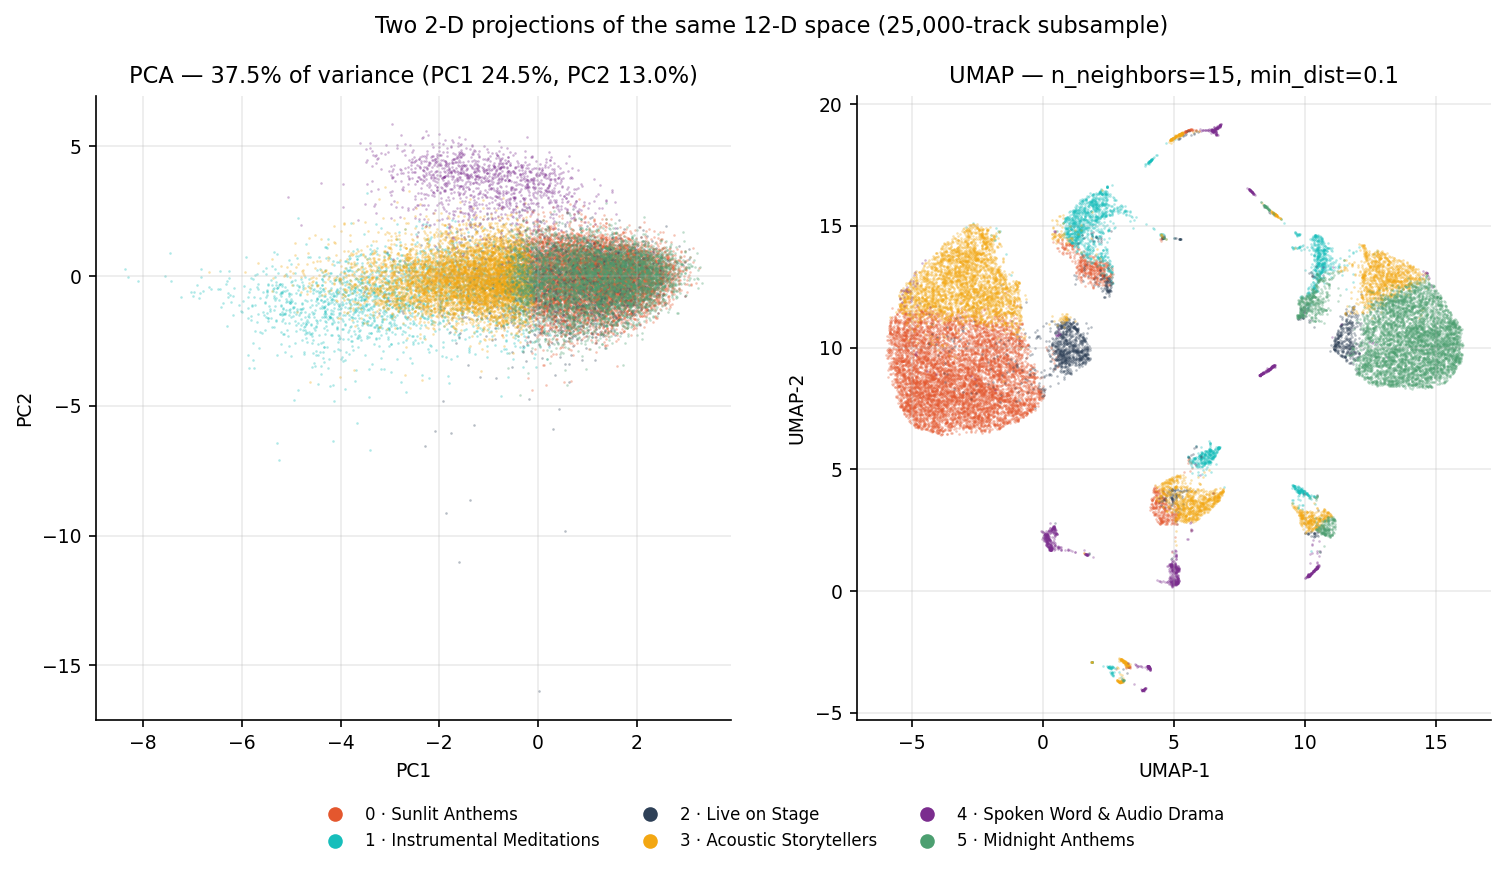

In [19]:
def tribe_legend(fig):
    fig.legend(handles=[Line2D([], [], marker="o", ls="", color=PALETTE[c], label=LABELS[c])
                        for c in range(K_FINAL)],
               loc="lower center", ncol=3, fontsize=8, frameon=False, bbox_to_anchor=(.5, -.07))

sub = tracks.iloc[np.random.default_rng(SEED).choice(len(tracks), 25000, replace=False)]
fig, ax = plt.subplots(1, 2, figsize=(12, 5.4))
for c in range(K_FINAL):
    sel = sub.cluster_id == c
    ax[0].scatter(sub.pca_x[sel],  sub.pca_y[sel],  s=1.5, c=PALETTE[c], alpha=.35, lw=0)
    ax[1].scatter(sub.umap_x[sel], sub.umap_y[sel], s=1.5, c=PALETTE[c], alpha=.35, lw=0)
evr = pca.explained_variance_ratio_
ax[0].set(title=f"PCA — {100*sum(evr):.1f}% of variance "
                f"(PC1 {100*evr[0]:.1f}%, PC2 {100*evr[1]:.1f}%)",
          xlabel="PC1", ylabel="PC2")
ax[1].set(title="UMAP — n_neighbors=15, min_dist=0.1", xlabel="UMAP-1", ylabel="UMAP-2")
tribe_legend(fig)
fig.suptitle("Two 2-D projections of the same 12-D space (25,000-track subsample)")
save_fig(fig, "05_pca_vs_umap.png")

UMAP preserves local neighbourhoods far better than PCA (0.938 vs 0.784). But its first axis
correlates **−0.91 with `mode`**: it has split the corpus into a major-key continent and a
minor-key continent, each containing a copy of every tribe. That is the next section.

## 8. Sensitivity — what the two non-continuous features cost

`mode` is binary and `time_signature` is near-constant. After standardization each carries
variance 1, the same as energy, and Euclidean geometry cannot tell that one of them is a
category rather than a quantity. This section re-runs everything on the 10 continuous
features — **still using the shared scaler**, just selecting 10 of its 12 output columns.

In [20]:
C = kmeans.cluster_centers_
cont = [AUDIO_FEATURES.index(f) for f in CONT10]
pairs = sorted([(i, j, round(float(np.linalg.norm(C[i][cont]-C[j][cont])), 3))
                for i in range(K_FINAL) for j in range(i+1, K_FINAL)], key=lambda t: t[2])
print("closest centroid pairs in the 10 continuous dimensions:", pairs[:3])
print("major-key share per cluster:", tracks.groupby('cluster_id')['mode'].mean().round(3).to_dict())

closest centroid pairs in the 10 continuous dimensions: [(0, 5, 0.232), (3, 5, 2.688), (0, 3, 2.777)]
major-key share per cluster: {0: 1.0, 1: 0.676, 2: 0.712, 3: 0.748, 4: 0.667, 5: 0.0}


In [21]:
km10 = KMeans(K_FINAL, random_state=SEED, n_init=10).fit(X10)
tracks["cluster10_id"] = km10.labels_
U10 = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                metric="euclidean", random_state=SEED).fit_transform(X10)
tracks["umap10_x"], tracks["umap10_y"] = U10[:,0], U10[:,1]
joblib.dump(km10, f"{OUT_DIR}/kmeans_10feature_sensitivity.joblib")

print("silhouette 12 vs 10:", round(silhouette_score(X, labels, sample_size=10000, random_state=SEED),4),
      "vs", round(silhouette_score(X10, km10.labels_, sample_size=10000, random_state=SEED),4))
print("NMI vs genre       :", round(normalized_mutual_info_score(tracks.genre_bucket[m], labels[m]),4),
      "vs", round(normalized_mutual_info_score(tracks.genre_bucket[m], km10.labels_[m]),4))
print("ARI between them   :", round(adjusted_rand_score(labels, km10.labels_),4))
print("corr(UMAP10-1,mode):", round(np.corrcoef(tracks.umap10_x, tracks['mode'])[0,1],3))

silhouette 12 vs 10: 0.161 vs 0.1867
NMI vs genre       : 0.1443 vs 0.1572
ARI between them   : 0.493
corr(UMAP10-1,mode): -0.017


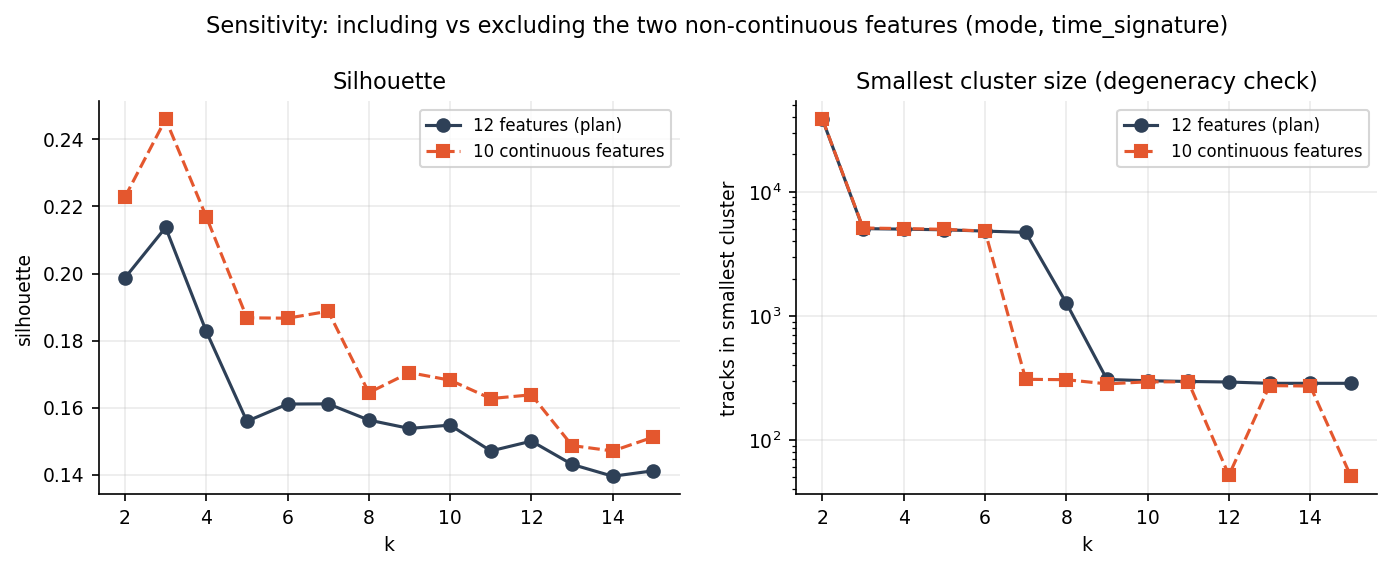

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(sw12.k, sw12.silhouette, "o-", color="#2E4057", label="12 features (plan)")
ax[0].plot(sw10.k, sw10.silhouette, "s--", color="#E4572E", label="10 continuous features")
ax[0].set(xlabel="k", ylabel="silhouette", title="Silhouette")
ax[0].legend(fontsize=8)
ax[1].plot(sw12.k, sw12.smallest_cluster, "o-", color="#2E4057", label="12 features (plan)")
ax[1].plot(sw10.k, sw10.smallest_cluster, "s--", color="#E4572E", label="10 continuous features")
ax[1].set(xlabel="k", ylabel="tracks in smallest cluster", yscale="log",
          title="Smallest cluster size (degeneracy check)")
ax[1].legend(fontsize=8)
fig.suptitle("Sensitivity: including vs excluding the two non-continuous features "
             "(mode, time_signature)", y=1.05)
save_fig(fig, "07_sensitivity_12_vs_10.png")

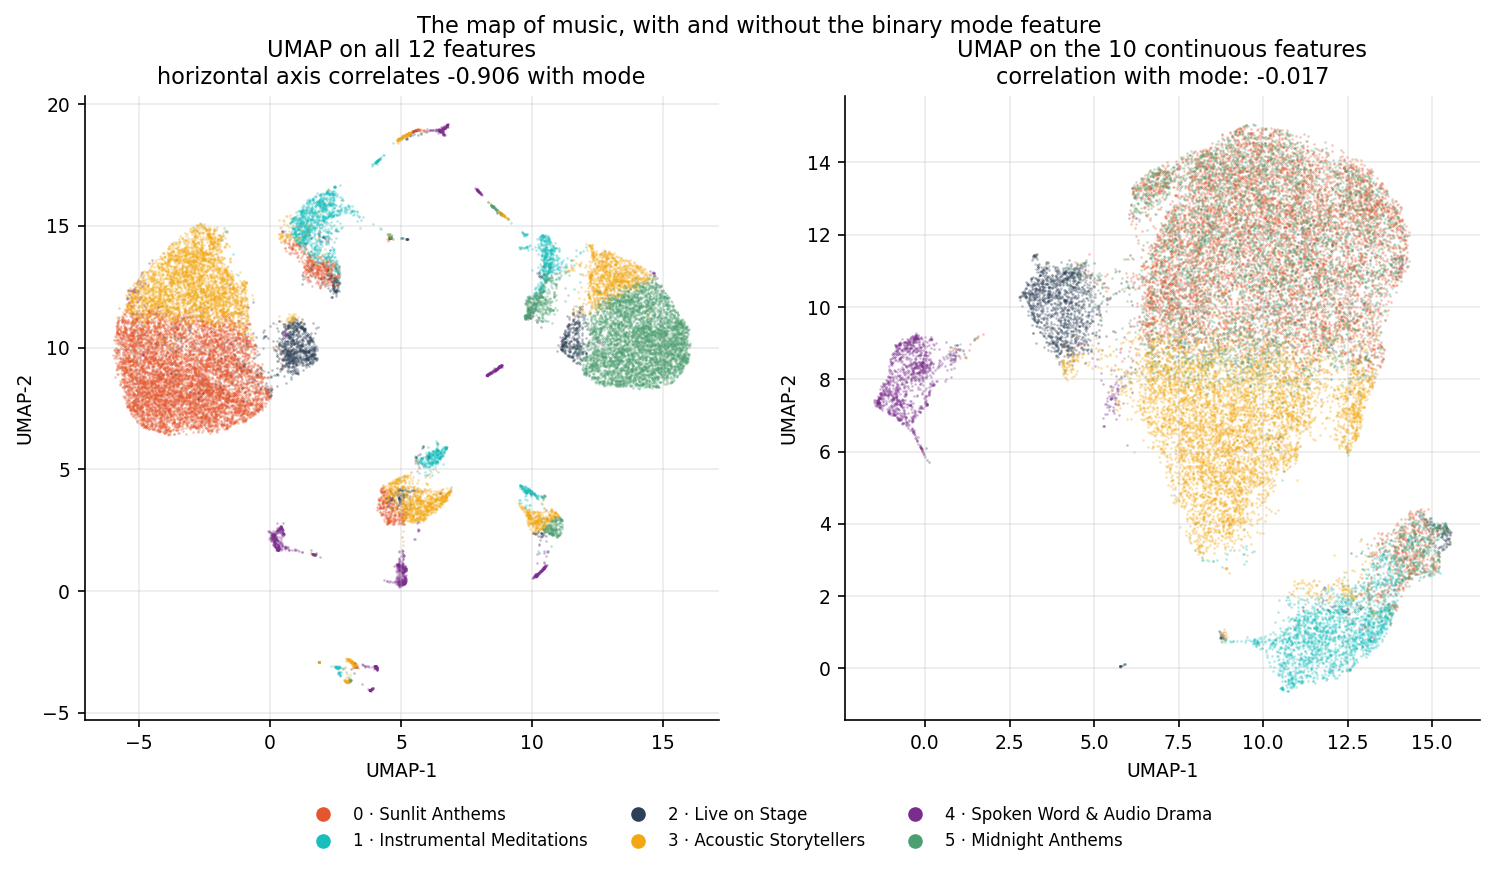

In [23]:
r12 = np.corrcoef(tracks.umap_x,   tracks["mode"])[0, 1]
r10 = np.corrcoef(tracks.umap10_x, tracks["mode"])[0, 1]
sub = tracks.iloc[np.random.default_rng(SEED).choice(len(tracks), 25000, replace=False)]

fig, ax = plt.subplots(1, 2, figsize=(12, 5.4))
for c in range(K_FINAL):
    sel = sub.cluster_id == c
    ax[0].scatter(sub.umap_x[sel],   sub.umap_y[sel],   s=1.5, c=PALETTE[c], alpha=.35, lw=0)
    ax[1].scatter(sub.umap10_x[sel], sub.umap10_y[sel], s=1.5, c=PALETTE[c], alpha=.35, lw=0)
ax[0].set(title=f"UMAP on all 12 features\nhorizontal axis correlates {r12:.3f} with mode",
          xlabel="UMAP-1", ylabel="UMAP-2")
ax[1].set(title=f"UMAP on the 10 continuous features\ncorrelation with mode: {r10:.3f}",
          xlabel="UMAP-1", ylabel="UMAP-2")
tribe_legend(fig)
fig.suptitle("The map of music, with and without the binary mode feature")
save_fig(fig, "08_umap_12_vs_10.png")

The 10-feature run is better on every internal measure and its map is free of the key-signature
split. The 12-feature solution is kept as the module's primary deliverable (it is what the
plan specifies, and it shares the exact feature space the DJ Engine's k-NN graph is built in),
with both projections exported so the frontend can choose.

## 9. Exports for the website and the report

In [24]:
tracks.to_parquet(f"{OUT_DIR}/tracks_clustered.parquet", index=False)

# ~5,000 songs for the in-browser map: proportional across clusters, stratified by decade inside each
TARGET, rng = 5000, np.random.default_rng(SEED)
sizes = tracks.cluster_id.value_counts().sort_index()
alloc = np.maximum((sizes/sizes.sum()*TARGET).round().astype(int), 150)
parts = []
for c in range(K_FINAL):
    sub  = tracks[tracks.cluster_id == c]
    n    = min(int(alloc[c]), len(sub)); frac = n/len(sub)
    take = pd.concat([g.sample(min(len(g), max(1, round(len(g)*frac))), random_state=SEED)
                      for _, g in sub.groupby("decade")])
    parts.append(take.sample(n, random_state=SEED) if len(take) > n else take)
sample = pd.concat(parts).sample(frac=1, random_state=SEED).reset_index(drop=True)

map_payload = {"meta": {"n_songs": int(len(sample)), "k": K_FINAL, "seed": SEED,
                        "primary_projection": "x,y = UMAP on all 12 features",
                        "alternative_projection": "x10,y10 = UMAP on the 10 continuous features"},
               "songs": [{"id": r.id, "song": r["name"], "artist": r.primary_artist_name,
                          "year": int(r.release_year), "decade": int(r.decade),
                          "popularity": int(r.popularity), "cluster_id": int(r.cluster_id),
                          "cluster_name": NAME[int(r.cluster_id)],
                          "x": round(float(r.umap_x),3),  "y": round(float(r.umap_y),3),
                          "x10": round(float(r.umap10_x),3), "y10": round(float(r.umap10_y),3),
                          "pca_x": round(float(r.pca_x),3), "pca_y": round(float(r.pca_y),3),
                          "cluster10_id": int(r.cluster10_id)} for _, r in sample.iterrows()]}
json.dump(map_payload, open(f"{OUT_DIR}/map_data.json","w"), separators=(",",":"))
print("map_data.json:", len(map_payload["songs"]), "songs")

map_data.json: 4999 songs


In [25]:
sil_sub = rng.choice(len(X), 20000, replace=False)
sv = silhouette_samples(X[sil_sub], labels[sil_sub])

meta = {"meta": {"k": K_FINAL, "seed": SEED, "n_tracks": int(len(tracks)),
                 "features": AUDIO_FEATURES,
                 "silhouette": round(float(silhouette_score(X, labels, sample_size=10000, random_state=SEED)), 4)},
        "clusters": []}
for c in range(K_FINAL):
    p = profiles[c]
    meta["clusters"].append({**p, "cluster_id": c, "name": NAME[c],
        "tagline": names[str(c)]["tagline"], "description": names[str(c)]["description"],
        "naming_justification": names[str(c)]["naming_justification"], "colour": PALETTE[c],
        "silhouette": round(float(sv[labels[sil_sub]==c].mean()), 3),
        "radar": {f: round(float(tracks[tracks.cluster_id==c][f].mean()), 3)
                  for f in RADAR_FEATURES},
        "share_by_decade": {str(d): float(by_dec_share.loc[d, c]) for d in by_dec_share.index},
        "count_by_decade": {str(d): int(by_dec_counts.loc[d, c]) for d in by_dec_counts.index}})
json.dump(meta, open(f"{OUT_DIR}/cluster_metadata.json","w"), indent=2)
print("cluster_metadata.json written")

cluster_metadata.json written
